In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 


In [2]:
from pathlib import Path

for path in [
    Path("datasets/Building_Permits_20261104.csv"),
    Path("../datasets/Building_Permits_20261104.csv"),
]:
    print(path.resolve(), path.exists())

C:\Users\yahar\OneDrive\Desktop\CityClient\CitySeattleProject\datasets\Building_Permits_20261104.csv True
C:\Users\yahar\OneDrive\Desktop\CityClient\datasets\Building_Permits_20261104.csv False


In [3]:
df = pd.read_csv("datasets/Building_Permits_20261104.csv")
electric_df = pd.read_csv("datasets/Electrical_Permits_20261104.csv")
land_df = pd.read_csv("datasets/Land_Use_Permits_20261104.csv")
water_df = pd.read_csv("datasets/Water_Service_Permits_20261104.csv")
trade_df = pd.read_csv("datasets/Trade_Permits_20261104.csv")


C:\Users\yahar\AppData\Local\Temp\ipykernel_6852\929258224.py:1: DtypeWarning: Columns (25,26,27,28,30,31,32) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("datasets/Building_Permits_20261104.csv")


In [4]:
df.head(5) 

,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,PermitTypeDesc,Description,HousingUnits,HousingUnitsRemoved,HousingUnitsAdded,EstProjectCost,...,PlanReviewCompleteDate,DaysIssuePermitCity,ReadyToIssueDate,Zoning,DwellingUnitType,StandardPlan,DependentBuilding,ParentPermitNum,HousingCategory,Development Site
0,3027973-EX,Commercial,Non-Residential,ECA and Shoreline Exemption/Street Improvement...,Street Improvement Exception,Exception/Exemption Request for: Land Use Appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
1,3028028-EX,Institutional,Non-Residential,ECA and Shoreline Exemption/Street Improvement...,Environmentally Critical Area Exemption,Exception/Exemption Request for: Land Use Appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
2,3028171-EX,Single Family/Duplex,Residential,ECA and Shoreline Exemption/Street Improvement...,Environmentally Critical Area Exemption,Exception/Exemption Request for: Land use appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
3,3028549-EX,Single Family/Duplex,Residential,ECA and Shoreline Exemption/Street Improvement...,Environmentally Critical Area Exemption,Exception/Exemption Request for: Land Use Appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
4,3028737-EX,Single Family/Duplex,Residential,ECA and Shoreline Exemption/Street Improvement...,Environmentally Critical Area Exemption,Exception/Exemption Request for: Land Use Appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN


In [5]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 194070 entries, 0 to 194069
Data columns (total 41 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   PermitNum                  194070 non-null  object 
 1   PermitClass                187128 non-null  object 
 2   PermitClassMapped          187128 non-null  object 
 3   PermitTypeMapped           194070 non-null  object 
 4   PermitTypeDesc             180891 non-null  object 
 5   Description                193273 non-null  object 
 6   HousingUnits               194070 non-null  int64  
 7   HousingUnitsRemoved        92421 non-null   float64
 8   HousingUnitsAdded          92421 non-null   float64
 9   EstProjectCost             158838 non-null  object 
 10  AppliedDate                147949 non-null  object 
 11  IssuedDate                 141112 non-null  object 
 12  ExpiresDate                141296 non-null  object 
 13  CompletedDate              10

In [6]:
df.isna().sum() 

PermitNum                         0
PermitClass                    6942
PermitClassMapped              6942
PermitTypeMapped                  0
PermitTypeDesc                13179
Description                     797
HousingUnits                      0
HousingUnitsRemoved          101649
HousingUnitsAdded            101649
EstProjectCost                35232
AppliedDate                   46121
IssuedDate                    52958
ExpiresDate                   52774
CompletedDate                 86018
StatusCurrent                     0
RelatedMup                   179653
OriginalAddress1                978
OriginalCity                   9109
OriginalState                  8967
OriginalZip                   10191
ContractorCompanyName        161955
Link                              0
Latitude                       1129
Longitude                      1129
Location1                      1129
TotalDaysPlanReview          160318
DaysInitialPlanReview        159828
DaysPlanReviewCity          

In [7]:
for col in df.columns:
    pct_missing = df[col].isnull().mean() * 100
    print(f"column {col}: {pct_missing:.2f}% missing values ")

column PermitNum: 0.00% missing values 
column PermitClass: 3.58% missing values 
column PermitClassMapped: 3.58% missing values 
column PermitTypeMapped: 0.00% missing values 
column PermitTypeDesc: 6.79% missing values 
column Description: 0.41% missing values 
column HousingUnits: 0.00% missing values 
column HousingUnitsRemoved: 52.38% missing values 
column HousingUnitsAdded: 52.38% missing values 
column EstProjectCost: 18.15% missing values 
column AppliedDate: 23.77% missing values 
column IssuedDate: 27.29% missing values 
column ExpiresDate: 27.19% missing values 
column CompletedDate: 44.32% missing values 
column StatusCurrent: 0.00% missing values 
column RelatedMup: 92.57% missing values 
column OriginalAddress1: 0.50% missing values 
column OriginalCity: 4.69% missing values 
column OriginalState: 4.62% missing values 
column OriginalZip: 5.25% missing values 
column ContractorCompanyName: 83.45% missing values 
column Link: 0.00% missing values 
column Latitude: 0.58% m

In [8]:
water_df.head(5) 

,Invoice #,Project Address / Work Address,Tap Size,Street Type,Payment Posting Date,ROW Permit Applied Date,ROW Permit Issued Date,Tentative Schedule Date,Completed Date
0,20260650,12531 28TH AVE NE - 12537 28TH AVE NE,4,Non-Arterial,10/14/2026,10/21/2026,10/27/2026,Pending,NaN
1,20260650,12531 28TH AVE NE - 12537 28TH AVE NE,4,Non-Arterial,10/14/2026,10/21/2026,10/27/2026,Pending,NaN
2,20250770,103 2ND AVE S,1,Non-Arterial,11/03/2025,NaN,NaN,Work Complete,02/17/2026
3,20260661,1520 NW 200TH ST,1.5,Arterial,10/07/2026,10/09/2026,11/02/2026,Pending,NaN
4,20250101,11055 14TH AVE SW - 1401 SW 111TH LN,1,Non-Arterial,03/20/2025,03/31/2025,04/09/2025,Work Complete,05/15/2025


In [9]:
water_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1871 entries, 0 to 1870
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Invoice #                       1871 non-null   int64 
 1   Project Address / Work Address  1871 non-null   object
 2   Tap Size                        1871 non-null   object
 3   Street Type                     1871 non-null   object
 4   Payment Posting Date            1871 non-null   object
 5   ROW Permit Applied Date         1855 non-null   object
 6   ROW Permit Issued Date          1852 non-null   object
 7   Tentative Schedule Date         1846 non-null   object
 8   Completed Date                  1560 non-null   object
dtypes: int64(1), object(8)
memory usage: 131.7+ KB


In [10]:
for col in water_df.columns:
    pct_missing = water_df[col].isnull().mean() * 100
    print(f"column {col}: {pct_missing:.2f}% missing values ")

column Invoice #: 0.00% missing values 
column Project Address / Work Address: 0.00% missing values 
column Tap Size: 0.00% missing values 
column Street Type: 0.00% missing values 
column Payment Posting Date: 0.00% missing values 
column ROW Permit Applied Date: 0.86% missing values 
column ROW Permit Issued Date: 1.02% missing values 
column Tentative Schedule Date: 1.34% missing values 
column Completed Date: 16.62% missing values 


In [11]:
electric_df.head(5)


,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,Description,EstProjectCost,AppliedDate,IssuedDate,ExpiresDate,CompletedDate,StatusCurrent,OriginalAddress1,OriginalCity,OriginalState,OriginalZip,ContractorCompanyName,Link,Latitude,Longitude,Location1
0,6001001-EL,Single Family/Duplex,Residential,Electrical,125 AMP SERVICE AND PICK-UP EXISTING CIRCUITS;...,NaN,2002-07-13,2002-07-13,2002-07-13,2005-03-10,Completed,5549 39TH AVE NE,SEATTLE,WA,98105.0,R B WHITE ELECTRIC INC,https://services.seattle.gov/portal/customize/...,47.669988,-122.286055,"(47.66998773, -122.28605486)"
1,6001002-EL,Institutional,Non-Residential,Electrical,"REMOVE/REINSTALL CLASS ROOM, CORRIDOR LIGHT FI...",NaN,2002-07-13,2002-07-13,2003-07-13,2002-08-07,Completed,700 18TH AVE E,SEATTLE,WA,98112.0,NORTH STAR ELECTRIC INC,https://services.seattle.gov/portal/customize/...,47.625484,-122.308291,"(47.625484, -122.30829128)"
2,6001003-EL,Commercial,Non-Residential,Electrical,PROVIDE CIRCUIT FOR NEW MIXER AND HOOK-UP.,NaN,2002-07-13,2002-07-13,2003-07-13,2004-06-03,Completed,3020 NE 45TH ST,SEATTLE,WA,98105.0,SPARTAN ELECTRIC SERVICES INC,https://services.seattle.gov/portal/customize/...,47.662055,-122.295462,"(47.66205506, -122.29546241)"
3,6001004-EL,Commercial,Non-Residential,Electrical,"BASEMENT LIGHTING, SWITCHING, RECEPTACLES, 1ST...",NaN,2002-07-13,2002-07-13,2003-07-13,2002-11-06,Completed,6504 20TH AVE NE,SEATTLE,WA,98115.0,NORTH STAR ELECTRIC INC,https://services.seattle.gov/portal/customize/...,47.676286,-122.306231,"(47.676286, -122.30623067)"
4,6001005-EL,Single Family/Duplex,Residential,Electrical,NEW 200 AMP SERVICE AND REWIRE FOR REMODEL AND...,NaN,2002-07-13,2002-07-13,2003-07-13,2003-07-10,Completed,119 NW 51ST ST,SEATTLE,WA,98107.0,GREEN LAKE ELECTRIC,https://services.seattle.gov/portal/customize/...,47.665582,-122.358001,"(47.66558189, -122.35800062)"


In [12]:
electric_df["PermitTypeMapped"].value_counts()

PermitTypeMapped
Electrical    504911
Name: count, dtype: int64

In [13]:
electric_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504911 entries, 0 to 504910
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   PermitNum              504911 non-null  object 
 1   PermitClass            484763 non-null  object 
 2   PermitClassMapped      484763 non-null  object 
 3   PermitTypeMapped       504911 non-null  object 
 4   Description            503271 non-null  object 
 5   EstProjectCost         206481 non-null  object 
 6   AppliedDate            304216 non-null  object 
 7   IssuedDate             502982 non-null  object 
 8   ExpiresDate            503054 non-null  object 
 9   CompletedDate          441398 non-null  object 
 10  StatusCurrent          504911 non-null  object 
 11  OriginalAddress1       504655 non-null  object 
 12  OriginalCity           465559 non-null  object 
 13  OriginalState          465792 non-null  object 
 14  OriginalZip            464342 non-nu

In [14]:
for col in electric_df.columns:
    pct_missing = electric_df[col].isnull().mean() * 100
    print(f"{col}: {pct_missing:.2f}% missing values ")

PermitNum: 0.00% missing values 
PermitClass: 3.99% missing values 
PermitClassMapped: 3.99% missing values 
PermitTypeMapped: 0.00% missing values 
Description: 0.32% missing values 
EstProjectCost: 59.11% missing values 
AppliedDate: 39.75% missing values 
IssuedDate: 0.38% missing values 
ExpiresDate: 0.37% missing values 
CompletedDate: 12.58% missing values 
StatusCurrent: 0.00% missing values 
OriginalAddress1: 0.05% missing values 
OriginalCity: 7.79% missing values 
OriginalState: 7.75% missing values 
OriginalZip: 8.03% missing values 
ContractorCompanyName: 11.38% missing values 
Link: 0.00% missing values 
Latitude: 0.18% missing values 
Longitude: 0.18% missing values 
Location1: 0.18% missing values 


In [15]:
land_df.head(5)

,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,PermitTypeDesc,Description,HousingUnits,HousingUnitsRemoved,HousingUnitsAdded,EstProjectCost,...,StatusCurrent,OriginalAddress1,OriginalCity,OriginalState,OriginalZip,ContractorCompanyName,Link,Latitude,Longitude,Location1
0,3001212-LU,Single Family/Duplex,Residential,Master Use Permit,NaN,PROJECT CANCELLED 12/8/2010 -- This short plat...,NaN,NaN,NaN,NaN,...,Canceled,6519 S BANGOR ST,SEATTLE,WA,98178.0,NaN,https://services.seattle.gov/portal/customize/...,47.505890,-122.251721,"(47.50588981, -122.25172068)"
1,3001271-LU,Single Family/Duplex,Residential,Master Use Permit,NaN,Land Use Permit to adjust the boundary between...,NaN,0.0,0,NaN,...,Completed,4226 1ST AVE NW,SEATTLE,WA,98107.0,NaN,https://services.seattle.gov/portal/customize/...,47.658500,-122.356929,"(47.65850007, -122.35692862)"
2,3001310-LU,Single Family/Duplex,Residential,Master Use Permit,NaN,Land use application to adjust the boundary be...,NaN,NaN,NaN,NaN,...,Completed,941 23RD AVE S,SEATTLE,WA,98144.0,NaN,https://services.seattle.gov/portal/customize/...,47.593378,-122.302622,"(47.59337775, -122.30262178)"
3,3001312-LU,NaN,NaN,Master Use Permit,NaN,Cancelled due to no activity for more than 9 y...,NaN,NaN,NaN,NaN,...,Canceled,3131 E MADISON ST,SEATTLE,WA,98112.0,NaN,https://services.seattle.gov/portal/customize/...,47.626489,-122.291301,"(47.62648852, -122.2913013)"
4,3001440-LU,Commercial,Non-Residential,Master Use Permit,NaN,PROJECT CANCELLED 5/23/2011 -- Project On Hold...,NaN,NaN,NaN,NaN,...,Canceled,9030 13TH AVE NW,SEATTLE,WA,98117.0,NaN,https://services.seattle.gov/portal/customize/...,47.695165,-122.372185,"(47.69516506, -122.37218535)"


In [16]:
land_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24675 entries, 0 to 24674
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   PermitNum              24675 non-null  object 
 1   PermitClass            23141 non-null  object 
 2   PermitClassMapped      23141 non-null  object 
 3   PermitTypeMapped       24675 non-null  object 
 4   PermitTypeDesc         2928 non-null   object 
 5   Description            24627 non-null  object 
 6   HousingUnits           5711 non-null   object 
 7   HousingUnitsRemoved    9697 non-null   float64
 8   HousingUnitsAdded      9697 non-null   object 
 9   EstProjectCost         13666 non-null  object 
 10  AppliedDate            14491 non-null  object 
 11  IssuedDate             12566 non-null  object 
 12  ExpiresDate            12527 non-null  object 
 13  DecisionDate           12897 non-null  object 
 14  StatusCurrent          24675 non-null  object 
 15  Or

In [17]:
for col in land_df.columns:
    pct_missing = land_df[col].isnull().mean() * 100
    print(f"column {col}: {pct_missing:.2f}% missing values ")

column PermitNum: 0.00% missing values 
column PermitClass: 6.22% missing values 
column PermitClassMapped: 6.22% missing values 
column PermitTypeMapped: 0.00% missing values 
column PermitTypeDesc: 88.13% missing values 
column Description: 0.19% missing values 
column HousingUnits: 76.86% missing values 
column HousingUnitsRemoved: 60.70% missing values 
column HousingUnitsAdded: 60.70% missing values 
column EstProjectCost: 44.62% missing values 
column AppliedDate: 41.27% missing values 
column IssuedDate: 49.07% missing values 
column ExpiresDate: 49.23% missing values 
column DecisionDate: 47.73% missing values 
column StatusCurrent: 0.00% missing values 
column OriginalAddress1: 0.85% missing values 
column OriginalCity: 4.26% missing values 
column OriginalState: 4.24% missing values 
column OriginalZip: 4.79% missing values 
column ContractorCompanyName: 95.49% missing values 
column Link: 0.00% missing values 
column Latitude: 0.88% missing values 
column Longitude: 0.88% mi

In [18]:
trade_df.head(5)

,PermitNum,PermitClass,PermitClassMapped,PermitType,PermitTypeMapped,Description,EstProjectCost,AppliedDate,IssuedDate,ExpiresDate,...,StatusCurrent,OriginalAddress1,OriginalCity,OriginalState,OriginalZip,ContractorCompanyName,Link,Latitude,Longitude,Location1
0,6001020-FR,Single Family/Duplex,Residential,Single-Family/Duplex Furnace,Trade,GAS TO GAS FURNACE CHANGE OUT,NaN,2002-07-15,2002-07-15,2004-01-15,...,Completed,3820 S MEAD ST,SEATTLE,WA,98118.0,GRIFFIS HEATING INCORPORATED,https://services.seattle.gov/portal/customize/...,47.550673,-122.283903,"(47.55067295, -122.28390337)"
1,6001028-CY,NaN,NaN,Conveyance,Trade,ELEVATOR INTERIOR,11000.0,2002-07-17,2002-07-18,2004-01-18,...,Completed,418 S JACKSON ST,SEATTLE,WA,98104.0,VERTICAL DIMENSIONS LLC,https://services.seattle.gov/portal/customize/...,47.599381,-122.327952,"(47.59938078, -122.32795152)"
2,6001035-BP,Commercial,Non-Residential,Boiler/Pressure Vessel,Trade,REPLACE EXISTING GAS BOILER,NaN,2002-07-15,2002-07-15,2004-01-15,...,Completed,800 E ROY ST,SEATTLE,WA,98102.0,WEST SEATTLE FURNACE SALES INC,https://services.seattle.gov/portal/customize/...,47.625306,-122.322085,"(47.62530645, -122.3220851)"
3,6001043-FR,Single Family/Duplex,Residential,Single-Family/Duplex Furnace,Trade,INSTALL FURNACE & DUCTWORK,NaN,2002-07-15,2002-07-15,2004-01-15,...,Completed,2108 41ST AVE SW,SEATTLE,WA,98116.0,SEATTLE SHEET METAL & HTG INC,https://services.seattle.gov/portal/customize/...,47.584940,-122.383352,"(47.58494045, -122.38335213)"
4,6001047-CY,NaN,NaN,Conveyance,Trade,ELEVATOR INTERIOR,11000.0,2002-07-17,2002-07-18,2004-01-18,...,Completed,418 S JACKSON ST,SEATTLE,WA,98104.0,VERTICAL DIMENSIONS LLC,https://services.seattle.gov/portal/customize/...,47.599381,-122.327952,"(47.59938078, -122.32795152)"


In [19]:
trade_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 289983 entries, 0 to 289982
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   PermitNum              289983 non-null  object 
 1   PermitClass            274682 non-null  object 
 2   PermitClassMapped      274682 non-null  object 
 3   PermitType             289983 non-null  object 
 4   PermitTypeMapped       289983 non-null  object 
 5   Description            289847 non-null  object 
 6   EstProjectCost         191196 non-null  float64
 7   AppliedDate            274955 non-null  object 
 8   IssuedDate             275155 non-null  object 
 9   ExpiresDate            278663 non-null  object 
 10  CompletedDate          218473 non-null  object 
 11  StatusCurrent          289983 non-null  object 
 12  OriginalAddress1       289758 non-null  object 
 13  OriginalCity           271426 non-null  object 
 14  OriginalState          271568 non-nu

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
land_df.duplicated().sum()

np.int64(1)

In [22]:
water_df.duplicated().sum()

np.int64(15)

In [23]:
electric_df.duplicated().sum()

np.int64(0)

In [24]:
trade_df.duplicated().sum()

np.int64(0)

### Building Dataset


In [25]:
build_df = df.copy() 

In [26]:
build_df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 194070 entries, 0 to 194069
Data columns (total 41 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   PermitNum                  194070 non-null  object 
 1   PermitClass                187128 non-null  object 
 2   PermitClassMapped          187128 non-null  object 
 3   PermitTypeMapped           194070 non-null  object 
 4   PermitTypeDesc             180891 non-null  object 
 5   Description                193273 non-null  object 
 6   HousingUnits               194070 non-null  int64  
 7   HousingUnitsRemoved        92421 non-null   float64
 8   HousingUnitsAdded          92421 non-null   float64
 9   EstProjectCost             158838 non-null  object 
 10  AppliedDate                147949 non-null  object 
 11  IssuedDate                 141112 non-null  object 
 12  ExpiresDate                141296 non-null  object 
 13  CompletedDate              10

In [27]:
na_align_check =  build_df[["TotalDaysPlanReview", "DaysInitialPlanReview",
                             "InitialReviewCompleteDate", "DaysPlanReviewCity",
                             "PlanReviewCompleteDate", "StatusCurrent", "PermitClass",
                             "PermitClassMapped"]]

In [28]:
result = na_align_check[na_align_check["TotalDaysPlanReview"].isna() & na_align_check["DaysInitialPlanReview"].isna() &
                        na_align_check["InitialReviewCompleteDate"].isna() & na_align_check["DaysPlanReviewCity"].isna() &
                        na_align_check["PlanReviewCompleteDate"].isna()]

result.head(20)

,TotalDaysPlanReview,DaysInitialPlanReview,InitialReviewCompleteDate,DaysPlanReviewCity,PlanReviewCompleteDate,StatusCurrent,PermitClass,PermitClassMapped
0,NaN,NaN,NaN,NaN,NaN,Completed,Commercial,Non-Residential
1,NaN,NaN,NaN,NaN,NaN,Completed,Institutional,Non-Residential
2,NaN,NaN,NaN,NaN,NaN,Completed,Single Family/Duplex,Residential
3,NaN,NaN,NaN,NaN,NaN,Completed,Single Family/Duplex,Residential
4,NaN,NaN,NaN,NaN,NaN,Completed,Single Family/Duplex,Residential
5,NaN,NaN,NaN,NaN,NaN,Corrections Required,Multifamily,Residential
6,NaN,NaN,NaN,NaN,NaN,Completed,Institutional,Non-Residential
7,NaN,NaN,NaN,NaN,NaN,Completed,Multifamily,Residential
8,NaN,NaN,NaN,NaN,NaN,Completed,Multifamily,Residential
9,NaN,NaN,NaN,NaN,NaN,Reviews In Process,Single Family/Duplex,Residential


In [29]:
result["StatusCurrent"].value_counts() 

StatusCurrent
Completed                    112683
Additional Info Requested     10315
Expired                        9268
Closed                         8862
Withdrawn                      5059
Canceled                       4470
Issued                         2517
Scheduled                      1882
Application Completed           712
Reviews Completed               430
Reviews In Process              375
Corrections Required            298
Ready for Intake                292
Ready for Issuance              277
Active                          268
Initiated                       216
Awaiting Information            168
Inspections Completed            70
Scheduled and Submitted          28
Approved to Occupy               15
Phase Issued                      9
Pending                           2
Corrections Submitted             2
Denied                            1
Name: count, dtype: int64

In [30]:
result["PermitClassMapped"].value_counts() 

PermitClassMapped
Residential        109736
Non-Residential     41542
Name: count, dtype: int64

In [31]:
build_df["PermitClassMapped"].value_counts() 

PermitClassMapped
Residential        134896
Non-Residential     52232
Name: count, dtype: int64

In [32]:
build_df["PermitClass"].value_counts() 

PermitClass
Single Family/Duplex    113005
Commercial               43363
Multifamily              21891
Institutional             5759
Industrial                2636
Vacant Land                474
Name: count, dtype: int64

In [33]:
build_df.head(5)

,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,PermitTypeDesc,Description,HousingUnits,HousingUnitsRemoved,HousingUnitsAdded,EstProjectCost,...,PlanReviewCompleteDate,DaysIssuePermitCity,ReadyToIssueDate,Zoning,DwellingUnitType,StandardPlan,DependentBuilding,ParentPermitNum,HousingCategory,Development Site
0,3027973-EX,Commercial,Non-Residential,ECA and Shoreline Exemption/Street Improvement...,Street Improvement Exception,Exception/Exemption Request for: Land Use Appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
1,3028028-EX,Institutional,Non-Residential,ECA and Shoreline Exemption/Street Improvement...,Environmentally Critical Area Exemption,Exception/Exemption Request for: Land Use Appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
2,3028171-EX,Single Family/Duplex,Residential,ECA and Shoreline Exemption/Street Improvement...,Environmentally Critical Area Exemption,Exception/Exemption Request for: Land use appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
3,3028549-EX,Single Family/Duplex,Residential,ECA and Shoreline Exemption/Street Improvement...,Environmentally Critical Area Exemption,Exception/Exemption Request for: Land Use Appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
4,3028737-EX,Single Family/Duplex,Residential,ECA and Shoreline Exemption/Street Improvement...,Environmentally Critical Area Exemption,Exception/Exemption Request for: Land Use Appl...,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN


In [34]:
date_columns = [
    "AppliedDate",
    "IssuedDate",
    "ExpiresDate",
    "CompletedDate",
    "InitialReviewCompleteDate",
    "PlanReviewCompleteDate",
    "ReadyToIssueDate"
]

for col in date_columns:
    build_df[col] = pd.to_datetime(build_df[col], errors="coerce")

C:\Users\yahar\AppData\Local\Temp\ipykernel_6852\614482973.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  build_df[col] = pd.to_datetime(build_df[col], errors="coerce")
C:\Users\yahar\AppData\Local\Temp\ipykernel_6852\614482973.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  build_df[col] = pd.to_datetime(build_df[col], errors="coerce")
C:\Users\yahar\AppData\Local\Temp\ipykernel_6852\614482973.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  build_df[col] = pd.to_datetime(build_df[col], errors="coerce")


In [35]:
#filter 2022 onwards
build_df = build_df[
    build_df["AppliedDate"] >= "2022-01-01"
].copy()

In [36]:
# Remove duplicate rows
build_df = build_df.drop_duplicates()

In [37]:
# Drop unnecessary columns
columns_to_drop = [
    "OriginalCity",
    "OriginalState",
    "OriginalZip",
    "ContractorCompanyName",
    "Link",
    "Latitude",
    "Longitude",
    "Location1",
    "ExpiresDate",
    "Description",
    "StandardPlan",
    "Development Site",
    "HousingUnits",
    "HousingUnitsAdded",
    "HousingUnitsRemoved"
]

build_df = build_df.drop(columns=columns_to_drop)

In [38]:
build_df.shape

(30083, 26)

# Electric dataset

In [39]:
elec_df = electric_df.copy()

In [40]:
elec_df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504911 entries, 0 to 504910
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   PermitNum              504911 non-null  object 
 1   PermitClass            484763 non-null  object 
 2   PermitClassMapped      484763 non-null  object 
 3   PermitTypeMapped       504911 non-null  object 
 4   Description            503271 non-null  object 
 5   EstProjectCost         206481 non-null  object 
 6   AppliedDate            304216 non-null  object 
 7   IssuedDate             502982 non-null  object 
 8   ExpiresDate            503054 non-null  object 
 9   CompletedDate          441398 non-null  object 
 10  StatusCurrent          504911 non-null  object 
 11  OriginalAddress1       504655 non-null  object 
 12  OriginalCity           465559 non-null  object 
 13  OriginalState          465792 non-null  object 
 14  OriginalZip            464342 non-nu

In [41]:
elec_df.isna().sum()

PermitNum                     0
PermitClass               20148
PermitClassMapped         20148
PermitTypeMapped              0
Description                1640
EstProjectCost           298430
AppliedDate              200695
IssuedDate                 1929
ExpiresDate                1857
CompletedDate             63513
StatusCurrent                 0
OriginalAddress1            256
OriginalCity              39352
OriginalState             39119
OriginalZip               40569
ContractorCompanyName     57463
Link                          0
Latitude                    914
Longitude                   914
Location1                   914
dtype: int64

In [42]:
elec_df.duplicated().sum() 

np.int64(0)

In [43]:
date_columns = [
    "AppliedDate",
    "IssuedDate",
    "ExpiresDate",
    "CompletedDate"
]

for col in date_columns:
    elec_df[col] = pd.to_datetime(elec_df[col], errors="coerce")

In [44]:
elec_df = elec_df[
    elec_df["AppliedDate"] >= "2022-01-01"
].copy()

In [45]:
elec_df = elec_df.drop_duplicates()

In [46]:
columns_to_drop = [
    "Description",
    "OriginalCity",
    "OriginalState",
    "OriginalZip",
    "ContractorCompanyName",
    "Link",
    "Latitude",
    "Longitude",
    "Location1",
    "ExpiresDate"
]

elec_df = elec_df.drop(columns=columns_to_drop)

In [47]:
elec_df.shape

(8043, 10)

# Water Service Application


In [48]:
wat_ser = water_df.copy() 

In [49]:
wat_ser.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1871 entries, 0 to 1870
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Invoice #                       1871 non-null   int64 
 1   Project Address / Work Address  1871 non-null   object
 2   Tap Size                        1871 non-null   object
 3   Street Type                     1871 non-null   object
 4   Payment Posting Date            1871 non-null   object
 5   ROW Permit Applied Date         1855 non-null   object
 6   ROW Permit Issued Date          1852 non-null   object
 7   Tentative Schedule Date         1846 non-null   object
 8   Completed Date                  1560 non-null   object
dtypes: int64(1), object(8)
memory usage: 131.7+ KB


In [50]:
wat_ser.isna().sum()

Invoice #                           0
Project Address / Work Address      0
Tap Size                            0
Street Type                         0
Payment Posting Date                0
ROW Permit Applied Date            16
ROW Permit Issued Date             19
Tentative Schedule Date            25
Completed Date                    311
dtype: int64

In [51]:
wat_ser.duplicated().sum()

np.int64(15)

In [52]:
wat_ser[wat_ser.duplicated(keep=False)]

,Invoice #,Project Address / Work Address,Tap Size,Street Type,Payment Posting Date,ROW Permit Applied Date,ROW Permit Issued Date,Tentative Schedule Date,Completed Date
0,20260650,12531 28TH AVE NE - 12537 28TH AVE NE,4,Non-Arterial,10/14/2026,10/21/2026,10/27/2026,Pending,NaN
1,20260650,12531 28TH AVE NE - 12537 28TH AVE NE,4,Non-Arterial,10/14/2026,10/21/2026,10/27/2026,Pending,NaN
20,20250837,747 BROADWAY,6,Non-Arterial,01/11/2026,Not Required,Not Required,Water Main Extension - N/A,NaN
22,20250837,747 BROADWAY,6,Non-Arterial,01/11/2026,Not Required,Not Required,Water Main Extension - N/A,NaN
82,20250798,118 W MERCER ST,4,Arterial,02/23/2026,02/26/2026,04/10/2026,Work Complete,08/22/2026
84,20250798,118 W MERCER ST,4,Arterial,02/23/2026,02/26/2026,04/10/2026,Work Complete,08/22/2026
145,20240365,13001 5TH AVE NE - 13001R 5TH AVE NE,2,Non-Arterial,06/12/2024,NaN,NaN,Work Complete,09/10/2025
148,20240365,13001 5TH AVE NE - 13001R 5TH AVE NE,2,Non-Arterial,06/12/2024,NaN,NaN,Work Complete,09/10/2025
212,20250795,3020 NE 45TH ST,6,Arterial,11/19/2025,Not Required,Not Required,Work Complete,04/04/2026
213,20250795,3020 NE 45TH ST,6,Arterial,11/19/2025,Not Required,Not Required,Work Complete,04/04/2026


In [53]:
wat_ser = wat_ser.drop_duplicates()

In [54]:
date_columns = [
    "Payment Posting Date",
    "ROW Permit Applied Date",
    "ROW Permit Issued Date",
    "Tentative Schedule Date",
    "Completed Date"
]

for col in date_columns:
    wat_ser[col + "_dt"] = pd.to_datetime(
        wat_ser[col],
        format="%m/%d/%Y",
        errors="coerce"
    )


In [55]:
wat_ser["Payment Posting Date_dt"].agg(["min", "max"])

min   2016-07-18
max   2026-10-31
Name: Payment Posting Date_dt, dtype: datetime64[ns]

In [56]:
wat_ser["ROW Permit Applied Date"].value_counts()

ROW Permit Applied Date
Not Required    118
12/10/2025       28
Processing       28
04/02/2026       26
07/09/2025       21
               ... 
09/10/2024        1
10/15/2024        1
09/30/2024        1
12/12/2024        1
10/21/2026        1
Name: count, Length: 390, dtype: int64

In [57]:
wat_ser = wat_ser[
    wat_ser["Payment Posting Date_dt"] >= "2022-01-01"
].copy() 

In [58]:
wat_ser.shape

(1852, 14)

In [59]:
wat_ser["Payment Posting Date_dt"].agg(["min", "max"])

min   2022-02-09
max   2026-10-31
Name: Payment Posting Date_dt, dtype: datetime64[ns]

In [60]:
wat_ser.columns.tolist()

['Invoice #',
 'Project Address / Work Address',
 'Tap Size',
 'Street Type',
 'Payment Posting Date',
 'ROW Permit Applied Date',
 'ROW Permit Issued Date',
 'Tentative Schedule Date',
 'Completed Date',
 'Payment Posting Date_dt',
 'ROW Permit Applied Date_dt',
 'ROW Permit Issued Date_dt',
 'Tentative Schedule Date_dt',
 'Completed Date_dt']

In [61]:
wat_ser = wat_ser.drop(columns = ["Payment Posting Date", "Completed Date"])

# Land Use Dataset

In [62]:
land_use = land_df.copy() 

In [63]:
land_use.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24675 entries, 0 to 24674
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   PermitNum              24675 non-null  object 
 1   PermitClass            23141 non-null  object 
 2   PermitClassMapped      23141 non-null  object 
 3   PermitTypeMapped       24675 non-null  object 
 4   PermitTypeDesc         2928 non-null   object 
 5   Description            24627 non-null  object 
 6   HousingUnits           5711 non-null   object 
 7   HousingUnitsRemoved    9697 non-null   float64
 8   HousingUnitsAdded      9697 non-null   object 
 9   EstProjectCost         13666 non-null  object 
 10  AppliedDate            14491 non-null  object 
 11  IssuedDate             12566 non-null  object 
 12  ExpiresDate            12527 non-null  object 
 13  DecisionDate           12897 non-null  object 
 14  StatusCurrent          24675 non-null  object 
 15  Or

In [64]:
land_df.head(5) 

,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,PermitTypeDesc,Description,HousingUnits,HousingUnitsRemoved,HousingUnitsAdded,EstProjectCost,...,StatusCurrent,OriginalAddress1,OriginalCity,OriginalState,OriginalZip,ContractorCompanyName,Link,Latitude,Longitude,Location1
0,3001212-LU,Single Family/Duplex,Residential,Master Use Permit,NaN,PROJECT CANCELLED 12/8/2010 -- This short plat...,NaN,NaN,NaN,NaN,...,Canceled,6519 S BANGOR ST,SEATTLE,WA,98178.0,NaN,https://services.seattle.gov/portal/customize/...,47.505890,-122.251721,"(47.50588981, -122.25172068)"
1,3001271-LU,Single Family/Duplex,Residential,Master Use Permit,NaN,Land Use Permit to adjust the boundary between...,NaN,0.0,0,NaN,...,Completed,4226 1ST AVE NW,SEATTLE,WA,98107.0,NaN,https://services.seattle.gov/portal/customize/...,47.658500,-122.356929,"(47.65850007, -122.35692862)"
2,3001310-LU,Single Family/Duplex,Residential,Master Use Permit,NaN,Land use application to adjust the boundary be...,NaN,NaN,NaN,NaN,...,Completed,941 23RD AVE S,SEATTLE,WA,98144.0,NaN,https://services.seattle.gov/portal/customize/...,47.593378,-122.302622,"(47.59337775, -122.30262178)"
3,3001312-LU,NaN,NaN,Master Use Permit,NaN,Cancelled due to no activity for more than 9 y...,NaN,NaN,NaN,NaN,...,Canceled,3131 E MADISON ST,SEATTLE,WA,98112.0,NaN,https://services.seattle.gov/portal/customize/...,47.626489,-122.291301,"(47.62648852, -122.2913013)"
4,3001440-LU,Commercial,Non-Residential,Master Use Permit,NaN,PROJECT CANCELLED 5/23/2011 -- Project On Hold...,NaN,NaN,NaN,NaN,...,Canceled,9030 13TH AVE NW,SEATTLE,WA,98117.0,NaN,https://services.seattle.gov/portal/customize/...,47.695165,-122.372185,"(47.69516506, -122.37218535)"


In [65]:
date_columns = [
    "AppliedDate",
    "IssuedDate",
    "ExpiresDate",
    "DecisionDate"
]

for col in date_columns:
    land_use[col] = pd.to_datetime(land_use[col], errors="coerce")

In [66]:
land_use = land_use[
    land_use["AppliedDate"] >= "2022-01-01"
].copy()

In [67]:
land_use.isna().sum()

PermitNum                   0
PermitClass                 1
PermitClassMapped           1
PermitTypeMapped            0
PermitTypeDesc           1824
Description                 0
HousingUnits              317
HousingUnitsRemoved       317
HousingUnitsAdded         317
EstProjectCost              2
AppliedDate                 0
IssuedDate                640
ExpiresDate               635
DecisionDate              530
StatusCurrent               0
OriginalAddress1            5
OriginalCity               37
OriginalState              26
OriginalZip                37
ContractorCompanyName    1824
Link                        0
Latitude                    5
Longitude                   5
Location1                   5
dtype: int64

In [68]:
land_use.duplicated().sum()

np.int64(0)

In [69]:
columns_to_drop = [
    "Description",
    "HousingUnits",
    "HousingUnitsRemoved",
    "HousingUnitsAdded",
    "EstProjectCost",
    "ExpiresDate",
    "OriginalCity",
    "OriginalState",
    "OriginalZip",
    "ContractorCompanyName",
    "Link",
    "Latitude",
    "Longitude",
    "Location1"
]

land_use = land_use.drop(columns=columns_to_drop)

In [70]:
land_use.shape

(1824, 10)

# Trade Dataset

In [71]:
trade = trade_df.copy() 

In [72]:
trade.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 289983 entries, 0 to 289982
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   PermitNum              289983 non-null  object 
 1   PermitClass            274682 non-null  object 
 2   PermitClassMapped      274682 non-null  object 
 3   PermitType             289983 non-null  object 
 4   PermitTypeMapped       289983 non-null  object 
 5   Description            289847 non-null  object 
 6   EstProjectCost         191196 non-null  float64
 7   AppliedDate            274955 non-null  object 
 8   IssuedDate             275155 non-null  object 
 9   ExpiresDate            278663 non-null  object 
 10  CompletedDate          218473 non-null  object 
 11  StatusCurrent          289983 non-null  object 
 12  OriginalAddress1       289758 non-null  object 
 13  OriginalCity           271426 non-null  object 
 14  OriginalState          271568 non-nu

In [73]:
trade.head(5)

,PermitNum,PermitClass,PermitClassMapped,PermitType,PermitTypeMapped,Description,EstProjectCost,AppliedDate,IssuedDate,ExpiresDate,...,StatusCurrent,OriginalAddress1,OriginalCity,OriginalState,OriginalZip,ContractorCompanyName,Link,Latitude,Longitude,Location1
0,6001020-FR,Single Family/Duplex,Residential,Single-Family/Duplex Furnace,Trade,GAS TO GAS FURNACE CHANGE OUT,NaN,2002-07-15,2002-07-15,2004-01-15,...,Completed,3820 S MEAD ST,SEATTLE,WA,98118.0,GRIFFIS HEATING INCORPORATED,https://services.seattle.gov/portal/customize/...,47.550673,-122.283903,"(47.55067295, -122.28390337)"
1,6001028-CY,NaN,NaN,Conveyance,Trade,ELEVATOR INTERIOR,11000.0,2002-07-17,2002-07-18,2004-01-18,...,Completed,418 S JACKSON ST,SEATTLE,WA,98104.0,VERTICAL DIMENSIONS LLC,https://services.seattle.gov/portal/customize/...,47.599381,-122.327952,"(47.59938078, -122.32795152)"
2,6001035-BP,Commercial,Non-Residential,Boiler/Pressure Vessel,Trade,REPLACE EXISTING GAS BOILER,NaN,2002-07-15,2002-07-15,2004-01-15,...,Completed,800 E ROY ST,SEATTLE,WA,98102.0,WEST SEATTLE FURNACE SALES INC,https://services.seattle.gov/portal/customize/...,47.625306,-122.322085,"(47.62530645, -122.3220851)"
3,6001043-FR,Single Family/Duplex,Residential,Single-Family/Duplex Furnace,Trade,INSTALL FURNACE & DUCTWORK,NaN,2002-07-15,2002-07-15,2004-01-15,...,Completed,2108 41ST AVE SW,SEATTLE,WA,98116.0,SEATTLE SHEET METAL & HTG INC,https://services.seattle.gov/portal/customize/...,47.584940,-122.383352,"(47.58494045, -122.38335213)"
4,6001047-CY,NaN,NaN,Conveyance,Trade,ELEVATOR INTERIOR,11000.0,2002-07-17,2002-07-18,2004-01-18,...,Completed,418 S JACKSON ST,SEATTLE,WA,98104.0,VERTICAL DIMENSIONS LLC,https://services.seattle.gov/portal/customize/...,47.599381,-122.327952,"(47.59938078, -122.32795152)"


In [74]:
trade.isna().sum()

PermitNum                    0
PermitClass              15301
PermitClassMapped        15301
PermitType                   0
PermitTypeMapped             0
Description                136
EstProjectCost           98787
AppliedDate              15028
IssuedDate               14828
ExpiresDate              11320
CompletedDate            71510
StatusCurrent                0
OriginalAddress1           225
OriginalCity             18557
OriginalState            18415
OriginalZip              18925
ContractorCompanyName    37441
Link                         0
Latitude                   418
Longitude                  418
Location1                  418
dtype: int64

In [75]:
trade.duplicated().sum() 

np.int64(0)

In [76]:
date_columns = [
    "AppliedDate",
    "IssuedDate",
    "ExpiresDate",
    "CompletedDate"
]

for col in date_columns:
    trade[col] = pd.to_datetime(trade[col], errors="coerce")

In [77]:
trade = trade[
    trade["AppliedDate"] >= "2022-01-01"
].copy()

In [78]:
columns_to_drop = [
    "Description",
    "OriginalCity",
    "OriginalState",
    "OriginalZip",
    "ContractorCompanyName",
    "Link",
    "Latitude",
    "Longitude",
    "Location1",
    "ExpiresDate"
]

trade = trade.drop(columns=columns_to_drop)

In [79]:
trade.info()

<class 'pandas.core.frame.DataFrame'>
Index: 92823 entries, 123207 to 289981
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   PermitNum          92823 non-null  object        
 1   PermitClass        92823 non-null  object        
 2   PermitClassMapped  92823 non-null  object        
 3   PermitType         92823 non-null  object        
 4   PermitTypeMapped   92823 non-null  object        
 5   EstProjectCost     92823 non-null  float64       
 6   AppliedDate        92823 non-null  datetime64[ns]
 7   IssuedDate         92088 non-null  datetime64[ns]
 8   CompletedDate      70192 non-null  datetime64[ns]
 9   StatusCurrent      92823 non-null  object        
 10  OriginalAddress1   92795 non-null  object        
dtypes: datetime64[ns](3), float64(1), object(7)
memory usage: 8.5+ MB


In [80]:
trade.shape

(92823, 11)

# Part 2: EDA

In [81]:
build_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30083 entries, 84721 to 194068
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   PermitNum                  30083 non-null  object        
 1   PermitClass                30083 non-null  object        
 2   PermitClassMapped          30083 non-null  object        
 3   PermitTypeMapped           30083 non-null  object        
 4   PermitTypeDesc             29365 non-null  object        
 5   EstProjectCost             30083 non-null  object        
 6   AppliedDate                30083 non-null  datetime64[ns]
 7   IssuedDate                 25875 non-null  datetime64[ns]
 8   CompletedDate              16292 non-null  datetime64[ns]
 9   StatusCurrent              30083 non-null  object        
 10  RelatedMup                 941 non-null    object        
 11  OriginalAddress1           30054 non-null  object        
 12  Tota

In [82]:
build_df["AppliedDate"].isna().sum()

np.int64(0)

In [83]:
build_df["IssuedDate"].isna().sum()

np.int64(4208)

In [84]:
with_4208_build = build_df.copy() 

In [85]:
build_df = build_df.dropna(subset=["IssuedDate"])

processing_duration = build_df["IssuedDate"] - build_df["AppliedDate"]

In [86]:
num_of_days = processing_duration.dt.days 

In [87]:
num_of_days.describe() 

count    25875.000000
mean       100.317527
std        322.987860
min     -46099.000000
25%          5.000000
50%         50.000000
75%        140.000000
max       1546.000000
dtype: float64

In [88]:
neg_rows = build_df.loc[num_of_days < 0]
neg_rows

,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,PermitTypeDesc,EstProjectCost,AppliedDate,IssuedDate,CompletedDate,StatusCurrent,...,NumberReviewCycles,InitialReviewCompleteDate,PlanReviewCompleteDate,DaysIssuePermitCity,ReadyToIssueDate,Zoning,DwellingUnitType,DependentBuilding,ParentPermitNum,HousingCategory
136947,6917270-CN,Single Family/Duplex,Residential,Building,Addition/Alteration,"1,000",2022-09-27,2022-09-20,2022-10-27,Completed,...,0.0,2022-09-19,2022-09-19,NaN,2022-09-20,NaN,NaN,0,NaN,Single-Family Add/Alt
161594,7089717-DM,Commercial,Non-Residential,Demolition,Demolition,0,2026-03-20,1900-01-01,NaT,Corrections Required,...,1.0,2026-04-08,NaT,NaN,NaT,NaN,NaN,0,NaN,NaN


In [89]:
num_of_days = num_of_days.drop(neg_rows.index)


In [90]:
num_of_days.describe()



count    25873.000000
mean       102.107293
std        147.743058
min          0.000000
25%          5.000000
50%         50.000000
75%        140.000000
max       1546.000000
dtype: float64

In [91]:
zero_days = num_of_days[num_of_days == 0]

In [92]:
print(len(zero_days)) 

2585


In [93]:
zero_day_projects = build_df.loc[zero_days.index]
zero_day_projects

,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,PermitTypeDesc,EstProjectCost,AppliedDate,IssuedDate,CompletedDate,StatusCurrent,...,NumberReviewCycles,InitialReviewCompleteDate,PlanReviewCompleteDate,DaysIssuePermitCity,ReadyToIssueDate,Zoning,DwellingUnitType,DependentBuilding,ParentPermitNum,HousingCategory
109059,6693186-CN,Single Family/Duplex,Residential,Building,New,"448,241",2023-07-27,2023-07-27,NaT,Issued,...,0.0,2022-05-03,2022-05-03,NaN,2023-07-26,NaN,NaN,0,NaN,NaN
109060,6693192-CN,Single Family/Duplex,Residential,Building,New,"407,290",2023-03-06,2023-03-06,NaT,Issued,...,0.0,2022-05-03,2022-05-03,NaN,2023-02-22,NaN,NaN,0,NaN,NaN
114046,6774759-DM,Multifamily,Residential,Demolition,Demolition,"200,000",2022-09-01,2022-09-01,2024-05-02,Completed,...,0.0,NaT,NaT,NaN,2022-09-01,NaN,NaN,0,NaN,NaN
128482,6842034-DM,Single Family/Duplex,Residential,Demolition,Demolition,"750,000",2022-06-17,2022-06-17,2023-09-13,Completed,...,0.0,NaT,NaT,NaN,2022-06-17,NR2,Detached Single-Family,0,NaN,NaN
130106,6693184-CN,Single Family/Duplex,Residential,Building,New,"481,860",2023-10-15,2023-10-15,NaT,Issued,...,0.0,2022-05-03,2022-05-03,NaN,2023-02-22,NaN,NaN,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
193973,7167734-CN,Single Family/Duplex,Residential,Building,Addition/Alteration,"3,600",2026-10-15,2026-10-15,NaT,Issued,...,0.0,NaT,NaT,NaN,2026-10-15,NaN,NaN,0,NaN,Single-Family Add/Alt
193975,7167742-CN,Single Family/Duplex,Residential,Building,Addition/Alteration,"150,000",2026-10-23,2026-10-23,NaT,Issued,...,0.0,NaT,NaT,NaN,2026-10-23,NaN,NaN,0,NaN,Single-Family Add/Alt
193986,7167916-CN,Commercial,Non-Residential,Building,Addition/Alteration,"15,000",2026-10-19,2026-10-19,NaT,Issued,...,0.0,NaT,NaT,NaN,2026-10-19,NaN,NaN,0,NaN,Commercial Add/Alt
194064,7168989-CN,Single Family/Duplex,Residential,Building,Addition/Alteration,"3,500",2026-10-23,2026-10-23,2026-10-27,Completed,...,0.0,NaT,NaT,NaN,2026-10-23,NaN,NaN,0,NaN,Single-Family Add/Alt


In [94]:
zero_day_projects["PermitClassMapped"].value_counts() 

PermitClassMapped
Residential        2358
Non-Residential     227
Name: count, dtype: int64

In [95]:
zero_day_projects["PermitTypeMapped"].value_counts() 

PermitTypeMapped
Building      2440
Demolition     144
Roof             1
Name: count, dtype: int64

In [96]:
zero_day_projects["PermitTypeDesc"].value_counts() 

PermitTypeDesc
Addition/Alteration                     2284
New                                      141
Demolition                               101
Temporary                                  8
Change of Use Only - No Construction       7
Deconstruction                             1
Name: count, dtype: int64

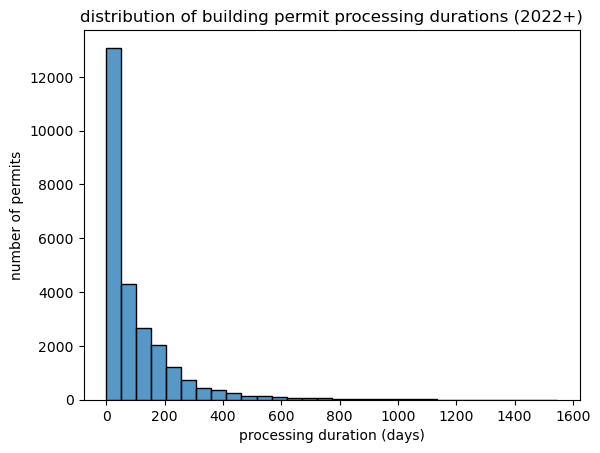

In [97]:
sns.histplot(data = num_of_days, bins  = 30)
plt.title("distribution of building permit processing durations (2022+)")
plt.xlabel("processing duration (days)")
plt.ylabel("number of permits")
plt.show() 

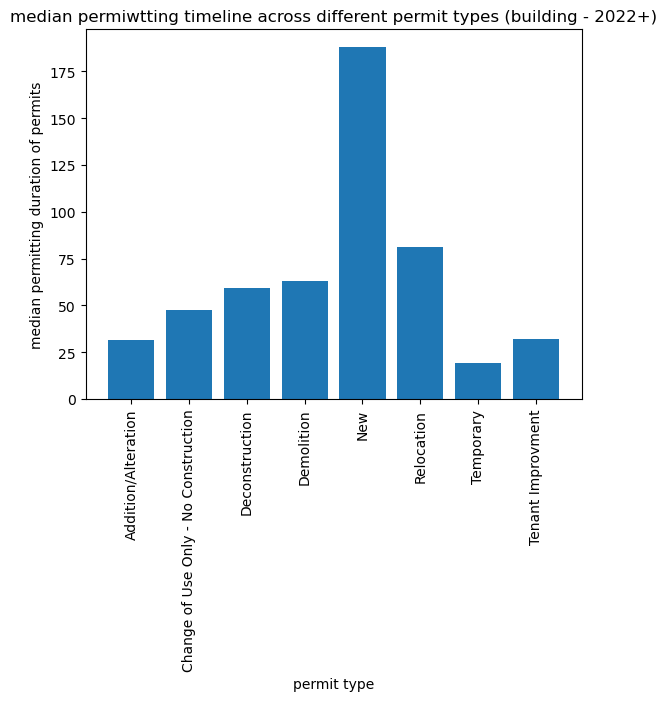

In [98]:
eda_df = build_df.copy()
eda_df = pd.concat([eda_df, num_of_days.rename("num_of_days")], axis = 1 )
med_durations = eda_df.groupby("PermitTypeDesc")["num_of_days"].median()

plt.bar(med_durations.index, med_durations.values)
plt.ylabel("median permitting duration of permits")
plt.xlabel("permit type")
plt.title("median permiwtting timeline across different permit types (building - 2022+)")
plt.xticks(rotation=90)
plt.show()


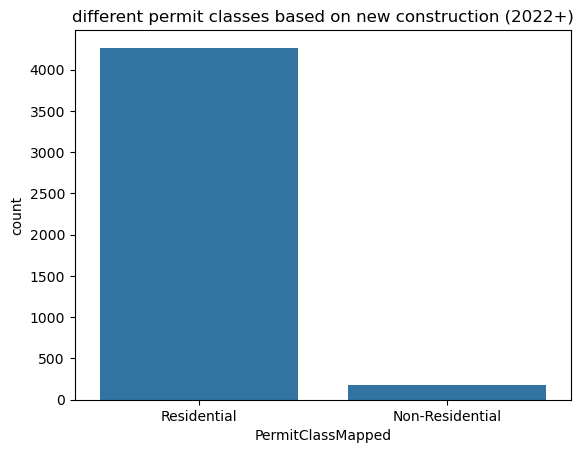

In [99]:
new_permits = eda_df.loc[eda_df["PermitTypeDesc"] == "New"]

plt.title("different permit classes based on new construction (2022+)")
sns.countplot(data = new_permits, x = "PermitClassMapped")
plt.show() 


# Electrical dataset 

In [100]:
elec_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8043 entries, 312932 to 504910
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   PermitNum          8043 non-null   object        
 1   PermitClass        8024 non-null   object        
 2   PermitClassMapped  8024 non-null   object        
 3   PermitTypeMapped   8043 non-null   object        
 4   EstProjectCost     8024 non-null   object        
 5   AppliedDate        8043 non-null   datetime64[ns]
 6   IssuedDate         7550 non-null   datetime64[ns]
 7   CompletedDate      6043 non-null   datetime64[ns]
 8   StatusCurrent      8043 non-null   object        
 9   OriginalAddress1   8040 non-null   object        
dtypes: datetime64[ns](3), object(7)
memory usage: 691.2+ KB


In [101]:
elec_eda_df = elec_df.copy() 

In [102]:
elec_eda_df["AppliedDate"].isna().sum()

np.int64(0)

In [103]:
elec_eda_df["IssuedDate"].isna().sum()

np.int64(493)

In [104]:
with_493 = elec_eda_df.copy() 

In [105]:
elec_eda_df = elec_eda_df.dropna(subset=["IssuedDate"])

In [106]:
processing_duration_elec = elec_eda_df["IssuedDate"] - elec_eda_df["AppliedDate"]

In [107]:
num_days_elec = processing_duration_elec.dt.days 

In [108]:
num_days_elec.describe() 

neg_days_elect = num_days_elec.loc[num_days_elec < 0]

neg_days_elect

312932   -2698
445141      -1
469315      -3
dtype: int64

In [109]:
num_days_elec = num_days_elec.drop(neg_days_elect.index)

In [110]:
num_days_elec.describe() 

count    7547.000000
mean       35.913343
std        65.389661
min         0.000000
25%         4.500000
50%        13.000000
75%        37.000000
max      1049.000000
dtype: float64

In [111]:
zero_days = num_days_elec[num_days_elec == 0]
zero_day_elec_proj = elec_eda_df.loc[zero_days.index]

zero_day_elec_proj

,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,EstProjectCost,AppliedDate,IssuedDate,CompletedDate,StatusCurrent,OriginalAddress1
376806,6875360-EL,Multifamily,Residential,Electrical,"140,000",2022-01-03,2022-01-03,2022-12-27,Completed,7510 43RD AVE S
376898,6875574-EL,Multifamily,Residential,Electrical,0,2022-01-03,2022-01-03,2022-12-27,Completed,7512 43RD AVE S
376900,6875576-EL,Multifamily,Residential,Electrical,0,2022-01-03,2022-01-03,2022-12-27,Completed,7508 43RD AVE S
376901,6875578-EL,Multifamily,Residential,Electrical,0,2022-01-03,2022-01-03,2022-12-27,Completed,7514 43RD AVE S
377131,6876207-EL,Commercial,Non-Residential,Electrical,"70,000",2022-01-27,2022-01-27,NaT,Withdrawn,12355 15TH AVE NE
...,...,...,...,...,...,...,...,...,...,...
501393,7162743-EL,NaN,NaN,Electrical,NaN,2026-09-25,2026-09-25,2026-09-25,Completed,9700 AURORA AVE N
502021,7164084-EL,Commercial,Non-Residential,Electrical,"7,150",2026-10-01,2026-10-01,NaT,Issued,1000 DEXTER AVE N
502100,7164234-EL,Commercial,Non-Residential,Electrical,"9,232",2026-10-01,2026-10-01,NaT,Issued,520 PIKE ST
502593,7165355-EL,Single Family/Duplex,Residential,Electrical,"19,560",2026-10-02,2026-10-02,2026-10-16,Completed,6854 51ST AVE NE


In [112]:
zero_day_elec_proj["PermitClassMapped"].value_counts() 

PermitClassMapped
Residential        447
Non-Residential    108
Name: count, dtype: int64

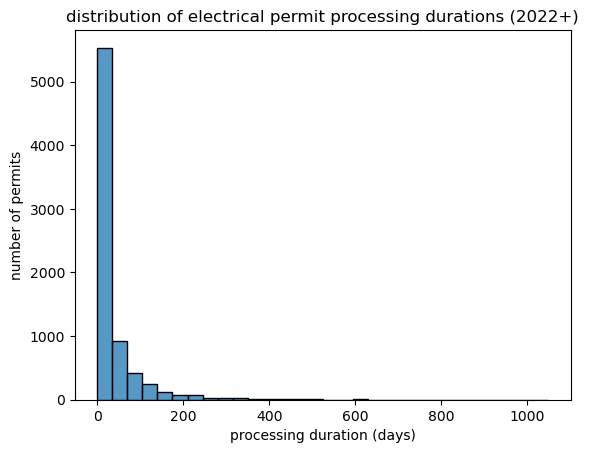

In [113]:
sns.histplot(data = num_days_elec, bins = 30)
plt.title("distribution of electrical permit processing durations (2022+)")
plt.xlabel("processing duration (days)")
plt.ylabel("number of permits")
plt.show() 

In [114]:
elec_eda_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7550 entries, 312932 to 504736
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   PermitNum          7550 non-null   object        
 1   PermitClass        7531 non-null   object        
 2   PermitClassMapped  7531 non-null   object        
 3   PermitTypeMapped   7550 non-null   object        
 4   EstProjectCost     7531 non-null   object        
 5   AppliedDate        7550 non-null   datetime64[ns]
 6   IssuedDate         7550 non-null   datetime64[ns]
 7   CompletedDate      6042 non-null   datetime64[ns]
 8   StatusCurrent      7550 non-null   object        
 9   OriginalAddress1   7547 non-null   object        
dtypes: datetime64[ns](3), object(7)
memory usage: 906.9+ KB


In [115]:
elec_eda_df["PermitClass"].value_counts()

PermitClass
Commercial              3411
Multifamily             1939
Single Family/Duplex    1612
Institutional            458
Industrial               108
Vacant Land                3
Name: count, dtype: int64

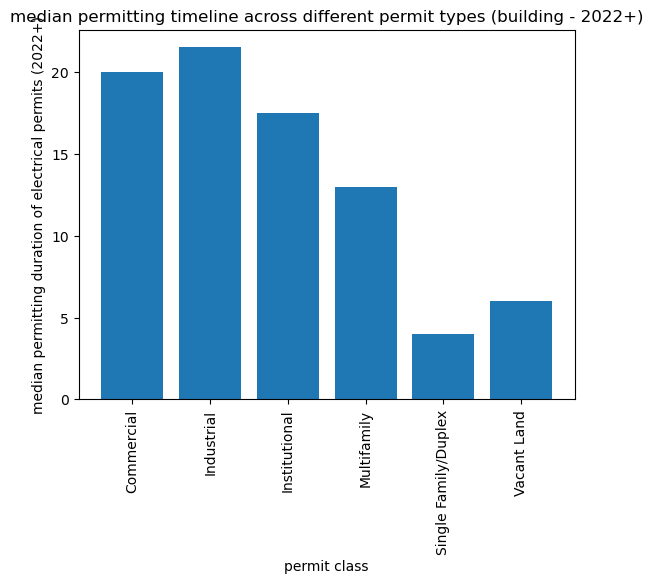

In [116]:
elec_eda_df = elec_eda_df.loc[:, elec_eda_df.columns != "num_days"].copy()
elec_eda_df["num_days"] = num_days_elec

median_duration_elec = elec_eda_df.groupby("PermitClass")["num_days"].median()

plt.bar(median_duration_elec.index, median_duration_elec.values)
plt.ylabel("median permitting duration of electrical permits (2022+)")
plt.xlabel("permit class")
plt.title("median permitting timeline across different permit types (building - 2022+)")
plt.xticks(rotation=90)
plt.show()

In [117]:
print(median_duration_elec)
print(median_duration_elec.index.shape)
print(median_duration_elec.values.shape)

PermitClass
Commercial              20.0
Industrial              21.5
Institutional           17.5
Multifamily             13.0
Single Family/Duplex     4.0
Vacant Land              6.0
Name: num_days, dtype: float64
(6,)
(6,)


# Water Service App. Dataset

In [118]:
water_eda = wat_ser.copy() 

In [119]:
water_eda.info() 

<class 'pandas.core.frame.DataFrame'>
Index: 1852 entries, 0 to 1870
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Invoice #                       1852 non-null   int64         
 1   Project Address / Work Address  1852 non-null   object        
 2   Tap Size                        1852 non-null   object        
 3   Street Type                     1852 non-null   object        
 4   ROW Permit Applied Date         1837 non-null   object        
 5   ROW Permit Issued Date          1834 non-null   object        
 6   Tentative Schedule Date         1827 non-null   object        
 7   Payment Posting Date_dt         1852 non-null   datetime64[ns]
 8   ROW Permit Applied Date_dt      1694 non-null   datetime64[ns]
 9   ROW Permit Issued Date_dt       1544 non-null   datetime64[ns]
 10  Tentative Schedule Date_dt      15 non-null     datetime64[ns]
 11  Completed

In [120]:
water_eda["ROW Permit Applied Date_dt"].isna().sum() 

np.int64(158)

In [121]:
water_eda["ROW Permit Issued Date_dt"].isna().sum() 

np.int64(308)

In [122]:
water_eda = water_eda.dropna(subset=["ROW Permit Issued Date_dt", "ROW Permit Applied Date_dt"])

processing_duration_wat = water_eda["ROW Permit Issued Date_dt"] - water_eda["ROW Permit Applied Date_dt"]


In [123]:
num_of_days_wat = processing_duration_wat.dt.days 
num_of_days_wat.describe() 

count    1544.000000
mean       44.352979
std        50.922448
min       -46.000000
25%        17.000000
50%        30.000000
75%        51.000000
max       758.000000
dtype: float64

In [124]:
neg_rows = water_eda.loc[num_of_days_wat < 0 ]
neg_rows

num_of_days_wat = num_of_days_wat.drop(neg_rows.index) 

In [125]:
num_of_days_wat.describe() 

count    1543.000000
mean       44.411536
std        50.886930
min         0.000000
25%        17.000000
50%        30.000000
75%        51.000000
max       758.000000
dtype: float64

In [126]:
zero_days_wat = num_of_days_wat[num_of_days_wat == 0]

In [127]:
water_eda.duplicated().sum()

np.int64(0)

In [128]:
zero_day_projects = water_eda.loc[zero_days_wat.index]
zero_day_projects

,Invoice #,Project Address / Work Address,Tap Size,Street Type,ROW Permit Applied Date,ROW Permit Issued Date,Tentative Schedule Date,Payment Posting Date_dt,ROW Permit Applied Date_dt,ROW Permit Issued Date_dt,Tentative Schedule Date_dt,Completed Date_dt
869,20250116,3001 S DAKOTA ST - 3003 S DAKOTA ST,0.75,Non-Arterial,05/08/2025,05/08/2025,Work Complete,2025-03-17,2025-05-08,2025-05-08,NaT,2025-05-14
870,20250116,3001 S DAKOTA ST - 3007 S DAKOTA ST,0.75,Non-Arterial,05/08/2025,05/08/2025,Work Complete,2025-03-17,2025-05-08,2025-05-08,NaT,2025-05-14
871,20250116,3001 S DAKOTA ST - 4100 30TH AVE S,0.75,Non-Arterial,05/08/2025,05/08/2025,Work Complete,2025-03-17,2025-05-08,2025-05-08,NaT,2025-05-14
872,20250116,3001 S DAKOTA ST - 4102 30TH AVE S,0.75,Non-Arterial,05/08/2025,05/08/2025,Work Complete,2025-03-17,2025-05-08,2025-05-08,NaT,2025-05-14
873,20250116,3001 S DAKOTA ST - 4104 30TH AVE S,0.75,Non-Arterial,05/08/2025,05/08/2025,Work Complete,2025-03-17,2025-05-08,2025-05-08,NaT,2025-05-14
874,20250116,3001 S DAKOTA ST - 4106 30TH AVE S,0.75,Non-Arterial,05/08/2025,05/08/2025,Work Complete,2025-03-17,2025-05-08,2025-05-08,NaT,2025-05-14
875,20250116,3001 S DAKOTA ST - 4108 30TH AVE S,0.75,Non-Arterial,05/08/2025,05/08/2025,Work Complete,2025-03-17,2025-05-08,2025-05-08,NaT,2025-05-14
876,20250116,3001 S DAKOTA ST - 4110 30TH AVE S,0.75,Non-Arterial,05/08/2025,05/08/2025,Work Complete,2025-03-17,2025-05-08,2025-05-08,NaT,2025-05-14


In [129]:
water_eda.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1544 entries, 0 to 1854
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Invoice #                       1544 non-null   int64         
 1   Project Address / Work Address  1544 non-null   object        
 2   Tap Size                        1544 non-null   object        
 3   Street Type                     1544 non-null   object        
 4   ROW Permit Applied Date         1544 non-null   object        
 5   ROW Permit Issued Date          1544 non-null   object        
 6   Tentative Schedule Date         1537 non-null   object        
 7   Payment Posting Date_dt         1544 non-null   datetime64[ns]
 8   ROW Permit Applied Date_dt      1544 non-null   datetime64[ns]
 9   ROW Permit Issued Date_dt       1544 non-null   datetime64[ns]
 10  Tentative Schedule Date_dt      15 non-null     datetime64[ns]
 11  Completed

In [130]:
zero_day_projects["Tap Size"].value_counts() 

Tap Size
0.75    8
Name: count, dtype: int64

In [131]:
water_eda["Tap Size"].value_counts() 

Tap Size
1       617
0.75    576
1.5     144
2        92
4        75
6        39
8         1
Name: count, dtype: int64

In [132]:
zero_day_projects["Street Type"].value_counts() 

Street Type
Non-Arterial    8
Name: count, dtype: int64

In [133]:
water_eda["Street Type"].value_counts() 

Street Type
Non-Arterial    1235
Arterial         309
Name: count, dtype: int64

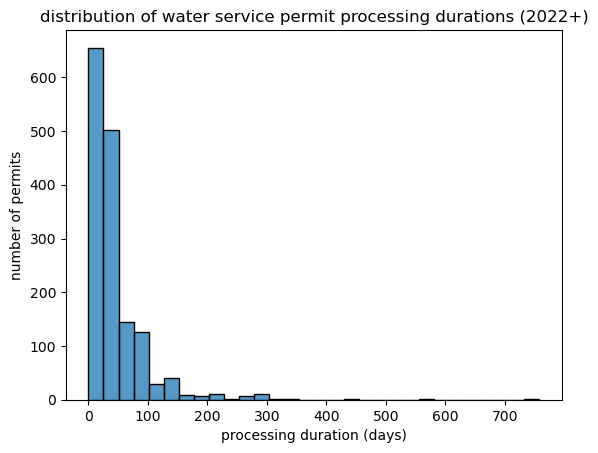

In [134]:
sns.histplot(data = num_of_days_wat, bins  = 30)
plt.title("distribution of water service permit processing durations (2022+)")
plt.xlabel("processing duration (days)")
plt.ylabel("number of permits")
plt.show() 

labels = [f"{size} (n={counts.loc[size]})" for size in medians.index]

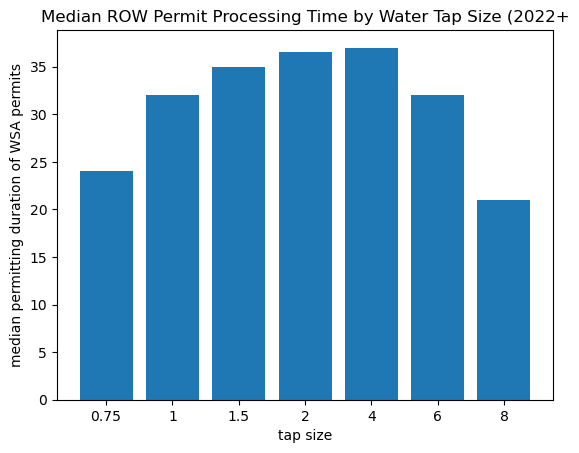

In [135]:

water_eda = pd.concat([water_eda, num_of_days_wat.rename("num_days")], axis = 1 )
med_durations_wat = water_eda.groupby("Tap Size")["num_days"].median() 

plt.bar(med_durations_wat.index , med_durations_wat.values)
plt.ylabel("median permitting duration of WSA permits")
plt.xlabel("tap size")
plt.title("Median ROW Permit Processing Time by Water Tap Size (2022+")
plt.show()

In [136]:
water_eda["Tap Size"].value_counts() 

Tap Size
1       617
0.75    576
1.5     144
2        92
4        75
6        39
8         1
Name: count, dtype: int64

# Trade Dataset

In [137]:
trade_eda = trade.copy() 

trade_eda.info()

<class 'pandas.core.frame.DataFrame'>
Index: 92823 entries, 123207 to 289981
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   PermitNum          92823 non-null  object        
 1   PermitClass        92823 non-null  object        
 2   PermitClassMapped  92823 non-null  object        
 3   PermitType         92823 non-null  object        
 4   PermitTypeMapped   92823 non-null  object        
 5   EstProjectCost     92823 non-null  float64       
 6   AppliedDate        92823 non-null  datetime64[ns]
 7   IssuedDate         92088 non-null  datetime64[ns]
 8   CompletedDate      70192 non-null  datetime64[ns]
 9   StatusCurrent      92823 non-null  object        
 10  OriginalAddress1   92795 non-null  object        
dtypes: datetime64[ns](3), float64(1), object(7)
memory usage: 8.5+ MB


In [138]:
trade_eda["AppliedDate"].isna().sum()

np.int64(0)

In [139]:
trade_eda["IssuedDate"].isna().sum()

np.int64(735)

In [140]:
trade_eda = trade_eda.dropna(subset=["IssuedDate", "AppliedDate"])
processing_duration_trade = trade_eda["IssuedDate"] - trade_eda["AppliedDate"]

In [141]:
num_of_days_trade = processing_duration_trade.dt.days

In [142]:
num_of_days_trade.describe() 

count    92088.000000
mean         4.002356
std         23.847630
min         -3.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       1240.000000
dtype: float64

In [143]:
neg_rows = trade_eda.loc[num_of_days_trade < 0 ]
neg_rows 

,PermitNum,PermitClass,PermitClassMapped,PermitType,PermitTypeMapped,EstProjectCost,AppliedDate,IssuedDate,CompletedDate,StatusCurrent,OriginalAddress1
268121,7109295-FS,Multifamily,Residential,Fire Sprinkler and Suppression,Trade,4000000.0,2025-09-30,2025-09-29,2026-04-04,Completed,2001 S NORMAN ST
268160,7109439-FS,Commercial,Non-Residential,Fire Sprinkler and Suppression,Trade,19000.0,2025-10-01,2025-09-30,NaT,Completed,1301 2ND AVE
268234,7109635-FS,Single Family/Duplex,Residential,Fire Sprinkler and Suppression,Trade,6000.0,2025-10-02,2025-10-01,2026-02-26,Completed,12562 B 17TH AVE NE
268393,7110078-FS,Multifamily,Residential,Fire Sprinkler and Suppression,Trade,781423.0,2025-10-06,2025-10-03,NaT,Issued,3827 14TH AVE W
279734,7142175-RF,Institutional,Non-Residential,Refrigeration,Trade,250000.0,2026-05-11,2026-05-08,2026-10-27,Completed,3923 OKANOGAN LN NE


In [144]:
num_of_days_trade = num_of_days_trade.drop(neg_rows.index)
num_of_days_trade.describe() 

count    92083.000000
mean         4.002672
std         23.848238
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       1240.000000
dtype: float64

In [145]:
zero_days = num_of_days_trade[num_of_days_trade == 0]
zero_days.value_counts().sum()

np.int64(82898)

In [146]:
num_of_days_trade.shape

(92083,)

In [147]:
zero_day_trade_proj = trade_eda.loc[zero_days.index]
zero_day_trade_proj

,PermitNum,PermitClass,PermitClassMapped,PermitType,PermitTypeMapped,EstProjectCost,AppliedDate,IssuedDate,CompletedDate,StatusCurrent,OriginalAddress1
123207,6668877-FR,Single Family/Duplex,Residential,Single-Family/Duplex Furnace,Trade,100.00,2023-09-09,2023-09-09,NaT,Withdrawn,700 5th AVE
178858,6841556-RF,Single Family/Duplex,Residential,Refrigeration,Trade,7093.74,2022-11-08,2022-11-08,2024-04-16,Completed,14324 25th AVE NE
182658,6854175-ME,Multifamily,Residential,Mechanical,Trade,1500.00,2022-01-13,2022-01-13,2022-02-09,Completed,8523 23rd AVE NE
185079,6861773-ME,Multifamily,Residential,Mechanical,Trade,3500.00,2022-02-16,2022-02-16,2022-05-13,Completed,940 W EMERSON ST
188561,6872192-ME,Multifamily,Residential,Mechanical,Trade,3000.00,2022-03-31,2022-03-31,2022-08-03,Completed,7322 RAINIER AVE S
...,...,...,...,...,...,...,...,...,...,...,...
289977,7170387-FR,Single Family/Duplex,Residential,Single-Family/Duplex Furnace,Trade,6000.00,2026-11-02,2026-11-02,NaT,Issued,3421 62ND AVE SW
289978,7170388-RF,Single Family/Duplex,Residential,Refrigeration,Trade,11597.45,2026-11-02,2026-11-02,NaT,Issued,3006 13TH AVE W
289979,7170391-RF,Single Family/Duplex,Residential,Refrigeration,Trade,6000.00,2026-11-02,2026-11-02,NaT,Issued,3421 62ND AVE SW
289980,7170397-RF,Single Family/Duplex,Residential,Refrigeration,Trade,10000.00,2026-11-02,2026-11-02,NaT,Issued,7550 41ST AVE NE


In [148]:
trade_eda.info() 

<class 'pandas.core.frame.DataFrame'>
Index: 92088 entries, 123207 to 289981
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   PermitNum          92088 non-null  object        
 1   PermitClass        92088 non-null  object        
 2   PermitClassMapped  92088 non-null  object        
 3   PermitType         92088 non-null  object        
 4   PermitTypeMapped   92088 non-null  object        
 5   EstProjectCost     92088 non-null  float64       
 6   AppliedDate        92088 non-null  datetime64[ns]
 7   IssuedDate         92088 non-null  datetime64[ns]
 8   CompletedDate      70192 non-null  datetime64[ns]
 9   StatusCurrent      92088 non-null  object        
 10  OriginalAddress1   92060 non-null  object        
dtypes: datetime64[ns](3), float64(1), object(7)
memory usage: 10.4+ MB


In [149]:
trade_eda["PermitClassMapped"].value_counts() 

PermitClassMapped
Residential        78364
Non-Residential    13724
Name: count, dtype: int64

In [150]:
trade_eda["PermitType"].value_counts()

PermitType
Single-Family/Duplex Furnace      37096
Refrigeration                     36326
Mechanical                         7933
Conveyance                         5602
Fire Sprinkler and Suppression     2672
Sign, Awning and Canopy            2442
Billboard                            16
Boiler/Pressure Vessel                1
Name: count, dtype: int64

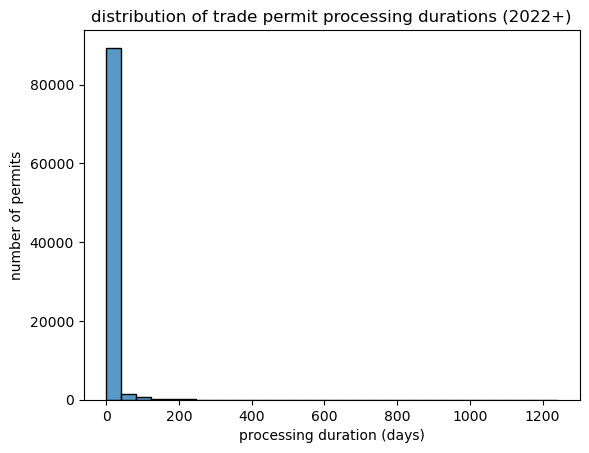

In [151]:
sns.histplot(data = num_of_days_trade, bins = 30)
plt.title("distribution of trade permit processing durations (2022+)")
plt.xlabel("processing duration (days)")
plt.ylabel("number of permits")
plt.show() 

In [152]:
trade_eda["PermitType"].value_counts() 

PermitType
Single-Family/Duplex Furnace      37096
Refrigeration                     36326
Mechanical                         7933
Conveyance                         5602
Fire Sprinkler and Suppression     2672
Sign, Awning and Canopy            2442
Billboard                            16
Boiler/Pressure Vessel                1
Name: count, dtype: int64

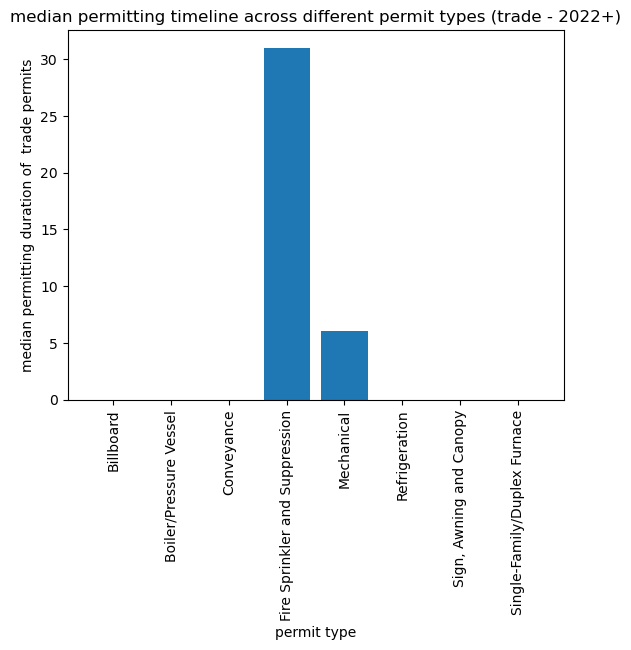

In [153]:
trade_eda = pd.concat([trade_eda, num_of_days_trade.rename("num_days")], axis = 1 )
med_durations_trade = trade_eda.groupby("PermitType")["num_days"].median() 


plt.bar(med_durations_trade.index, med_durations_trade.values)
plt.ylabel("median permitting duration of  trade permits")
plt.xlabel("permit type")
plt.title("median permitting timeline across different permit types (trade - 2022+)")
plt.xticks(rotation=90)
plt.show()


# Land Use 

In [154]:
land_use.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1824 entries, 11956 to 24666
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   PermitNum          1824 non-null   object        
 1   PermitClass        1823 non-null   object        
 2   PermitClassMapped  1823 non-null   object        
 3   PermitTypeMapped   1824 non-null   object        
 4   PermitTypeDesc     0 non-null      object        
 5   AppliedDate        1824 non-null   datetime64[ns]
 6   IssuedDate         1184 non-null   datetime64[ns]
 7   DecisionDate       1294 non-null   datetime64[ns]
 8   StatusCurrent      1824 non-null   object        
 9   OriginalAddress1   1819 non-null   object        
dtypes: datetime64[ns](3), object(7)
memory usage: 156.8+ KB


In [155]:
land_eda = land_use.copy() 

In [156]:
land_eda.info() 

<class 'pandas.core.frame.DataFrame'>
Index: 1824 entries, 11956 to 24666
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   PermitNum          1824 non-null   object        
 1   PermitClass        1823 non-null   object        
 2   PermitClassMapped  1823 non-null   object        
 3   PermitTypeMapped   1824 non-null   object        
 4   PermitTypeDesc     0 non-null      object        
 5   AppliedDate        1824 non-null   datetime64[ns]
 6   IssuedDate         1184 non-null   datetime64[ns]
 7   DecisionDate       1294 non-null   datetime64[ns]
 8   StatusCurrent      1824 non-null   object        
 9   OriginalAddress1   1819 non-null   object        
dtypes: datetime64[ns](3), object(7)
memory usage: 156.8+ KB


In [157]:
land_eda["AppliedDate"].isna().sum() 

np.int64(0)

In [158]:
land_eda["IssuedDate"].isna().sum() 

np.int64(640)

In [159]:
land_eda = land_eda.dropna(subset=["IssuedDate"])
processing_duration_land = land_eda["IssuedDate"] - land_eda["AppliedDate"]

In [160]:
num_days_land = processing_duration_land.dt.days 

In [161]:
num_days_land.describe() 

count    1184.000000
mean      310.692568
std       209.577476
min        51.000000
25%       173.000000
50%       243.500000
75%       375.000000
max      1551.000000
dtype: float64

In [162]:
zero_days = num_days_land[num_days_land == 0]

In [163]:
zero_day_land_proj = land_eda.loc[zero_days.index]
zero_day_land_proj

,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,PermitTypeDesc,AppliedDate,IssuedDate,DecisionDate,StatusCurrent,OriginalAddress1


In [164]:
land_eda.info() 

<class 'pandas.core.frame.DataFrame'>
Index: 1184 entries, 15103 to 24387
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   PermitNum          1184 non-null   object        
 1   PermitClass        1183 non-null   object        
 2   PermitClassMapped  1183 non-null   object        
 3   PermitTypeMapped   1184 non-null   object        
 4   PermitTypeDesc     0 non-null      object        
 5   AppliedDate        1184 non-null   datetime64[ns]
 6   IssuedDate         1184 non-null   datetime64[ns]
 7   DecisionDate       1180 non-null   datetime64[ns]
 8   StatusCurrent      1184 non-null   object        
 9   OriginalAddress1   1179 non-null   object        
dtypes: datetime64[ns](3), object(7)
memory usage: 134.0+ KB


In [165]:
land_eda["PermitClass"].value_counts() 

PermitClass
Single Family/Duplex    732
Multifamily             286
Commercial               94
Institutional            36
Industrial               23
Vacant Land              12
Name: count, dtype: int64

In [166]:
land_eda = land_eda.drop(columns = "PermitTypeDesc")

In [167]:
land_eda

,PermitNum,PermitClass,PermitClassMapped,PermitTypeMapped,AppliedDate,IssuedDate,DecisionDate,StatusCurrent,OriginalAddress1
15103,3030258-LU,Multifamily,Residential,Master Use Permit,2023-02-17,2026-01-20,2025-10-14,Issued,9400 35TH AVE NE
15535,3032473-LU,Multifamily,Residential,Master Use Permit,2022-01-21,2023-05-04,2022-10-27,Completed,7900 GREEN LAKE DR N
16192,3033307-LU,Multifamily,Residential,Master Use Permit,2022-01-13,2023-02-02,2022-11-21,Issued,8415 DELRIDGE WAY SW
17204,3034000-LU,Institutional,Non-Residential,Master Use Permit,2024-11-21,2025-11-17,2025-10-16,Issued,3655 WALLA WALLA RD NE
17254,3034063-LU,Institutional,Non-Residential,Master Use Permit,2022-07-25,2023-08-04,2023-05-22,Issued,8401 8TH AVE S
...,...,...,...,...,...,...,...,...,...
24330,3044068-LU,Single Family/Duplex,Residential,Master Use Permit,2026-04-20,2026-09-28,2026-07-02,Completed,902 18TH AVE
24334,3044072-LU,Single Family/Duplex,Residential,Master Use Permit,2026-05-12,2026-10-23,2026-09-21,Completed,5209 RENTON AVE S
24376,3044151-LU,Single Family/Duplex,Residential,Master Use Permit,2026-05-08,2026-09-29,2026-08-13,Completed,3256A NW MARKET ST
24380,3044158-LU,Single Family/Duplex,Residential,Master Use Permit,2026-05-22,2026-10-06,2026-08-20,Completed,5903 41ST AVE SW


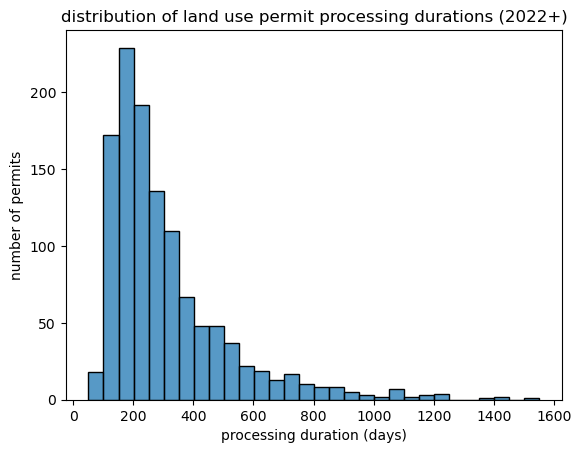

In [168]:
sns.histplot(data = num_days_land, bins  = 30)
plt.title("distribution of land use permit processing durations (2022+)")
plt.xlabel("processing duration (days)")
plt.ylabel("number of permits")
plt.show() 

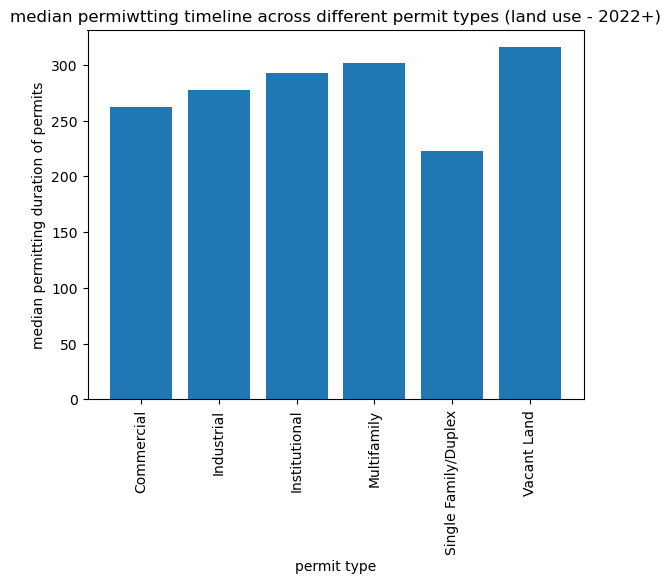

In [169]:
land_eda = pd.concat([land_eda, num_days_land.rename("num_days")], axis = 1 )
med_durations_land = land_eda.groupby("PermitClass")["num_days"].median()

plt.bar(med_durations_land.index, med_durations_land.values)
plt.ylabel("median permitting duration of permits")
plt.xlabel("permit type")
plt.title("median permiwtting timeline across different permit types (land use - 2022+)")
plt.xticks(rotation=90)
plt.show()

## Part 3: Summary Table 

In [170]:
print(med_durations)

PermitTypeDesc
Addition/Alteration                      31.5
Change of Use Only - No Construction     47.5
Deconstruction                           59.5
Demolition                               63.0
New                                     188.0
Relocation                               81.0
Temporary                                19.0
Tenant Improvment                        32.0
Name: num_of_days, dtype: float64


In [171]:
median_days_build = num_of_days.median() 
median_days_water = num_of_days_wat.median()
median_days_electric = num_days_elec.median()
median_days_trade = num_of_days_trade.median()
median_days_land  =  num_days_land.median() 

valid_build = num_of_days.count() 
valid_water = num_of_days_wat.count() 
valid_electric = num_days_elec.count()
valid_trade = num_of_days_trade.count()
valid_land = num_days_land.count()

build_calc = len(zero_days) / num_of_days.count() * 100 

map_columns_median = {
    "Permit Dataset": ["Building", "Water Service Application", "Electric", "Trade", "Land Use"],
    "Median Duration (Days)": [median_days_build, median_days_water, median_days_electric, median_days_trade, median_days_land],
    "# of Permits ": [valid_build, valid_water, valid_electric, valid_trade, valid_land]
}

summ_df = pd.DataFrame(map_columns_median)
summ_df

,Permit Dataset,Median Duration (Days),# of Permits
0,Building,50.0,25873
1,Water Service Application,30.0,1543
2,Electric,13.0,7547
3,Trade,0.0,92083
4,Land Use,243.5,1184


In [172]:
print(len(zero_days))

0


In [173]:
print(build_calc)

0.0
